# Experiment 5 — Relationship Between Analogue Quality and Forecast Accuracy

sMOA Python reference: **N=18.387 attempts/family, k=5, m=4.422, GAM, omit bridge, seed0**.
50 bang ×50 fixed origins ×4 horizons =10.000 forecast instances, khớp E2/E4.

Mục tiêu: distance nhỏ có đi cùng error nhỏ? Có good-match/bad-forecast cases?
Quan hệ thay đổi theo horizon? Distance có thêm thông tin chẩn đoán rủi ro ngoài phase/scale/volatility?

Notebook đọc các artifacts thực tế, không sinh lại synthetic hoặc forecast. [README](README.md) ghi thiết kế và cách chạy.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/analogue_quality/experiment_5.py').exists())
OUT = ROOT/'outputs/experiment_5'
progress = json.loads((OUT/'progress.json').read_text())
if progress['status'] != 'complete': raise RuntimeError('Experiment 5 chưa hoàn tất; xem progress.json/run.log')
def table(name): return pd.read_csv(OUT/(name+'.csv'))
def figure(name): display(Image(filename=str(OUT/'figures'/(name+'.png'))))
display(pd.Series({k:v for k,v in progress.items() if k not in ['risk_fits','artifacts_sha256']}))
corr=table('correlations');risk=table('risk_scores');groups=table('grouped_errors')


status                                                             complete
verified_forecasts                                                    10000
cases                                                                  2500
train_cases                                                            1300
test_cases                                                             1150
embargo_cases                                                            50
first_test_origin                                                2021-01-23
good_match_threshold                                               0.034042
distance_bin_cuts         [0.03404202991481659, 0.046987841604100876, 0....
cases_sha256              0a2ff4fd47235bd177b7037bbe165db46dfb759723e19b...
analysis_source_sha256    d54b920a4ecd78df71fedf59a8f95e76ebbf669c4c76e9...
wall_seconds                                                       4.459082
completed_utc                              2026-10-31T12:36:47.474046+00:00
dtype: objec

## 1. Distance và error ở cùng forecast instance

Minimum, mean, median L1 của top m được lưu ở mỗi origin. Mean distance được bổ sung bằng exact replay và đối chiếu point forecasts/min/median/max với E2.

Scaled distance = distance / (k × level_scale), level_scale=max(mean(last 6 raw observations floored at 1),1).
Error scale dùng mean(last 4 floored observations) như E4. Hai scales liên quan nhau, nên tương quan giữa ratios có thể do scale; phải đọc raw/scaled, strata và partial rank association cùng nhau.

Mỗi horizon phân tích riêng. Case-level pooled score lấy mean error qua 4 horizons, không coi 10.000 dòng là 10.000 origins độc lập.

,seed,scope,stratum,horizon,distance,error,cases,states,rho,lo,hi
7,0,all,all,1,mean_distance_scaled,normalized_absolute_error,2500,50,0.237268,0.198338,0.271730
12,0,all,context_adjusted,1,mean_distance_scaled,normalized_absolute_error,2500,50,0.010150,NaN,NaN
20,0,all,all,2,mean_distance_scaled,normalized_absolute_error,2500,50,0.239018,0.197491,0.272770
25,0,all,context_adjusted,2,mean_distance_scaled,normalized_absolute_error,2500,50,0.005582,NaN,NaN
33,0,all,all,3,mean_distance_scaled,normalized_absolute_error,2500,50,0.204062,0.166925,0.239666
38,0,all,context_adjusted,3,mean_distance_scaled,normalized_absolute_error,2500,50,-0.011564,NaN,NaN
46,0,all,all,4,mean_distance_scaled,normalized_absolute_error,2500,50,0.190586,0.145108,0.230266
51,0,all,context_adjusted,4,mean_distance_scaled,normalized_absolute_error,2500,50,-0.038330,NaN,NaN


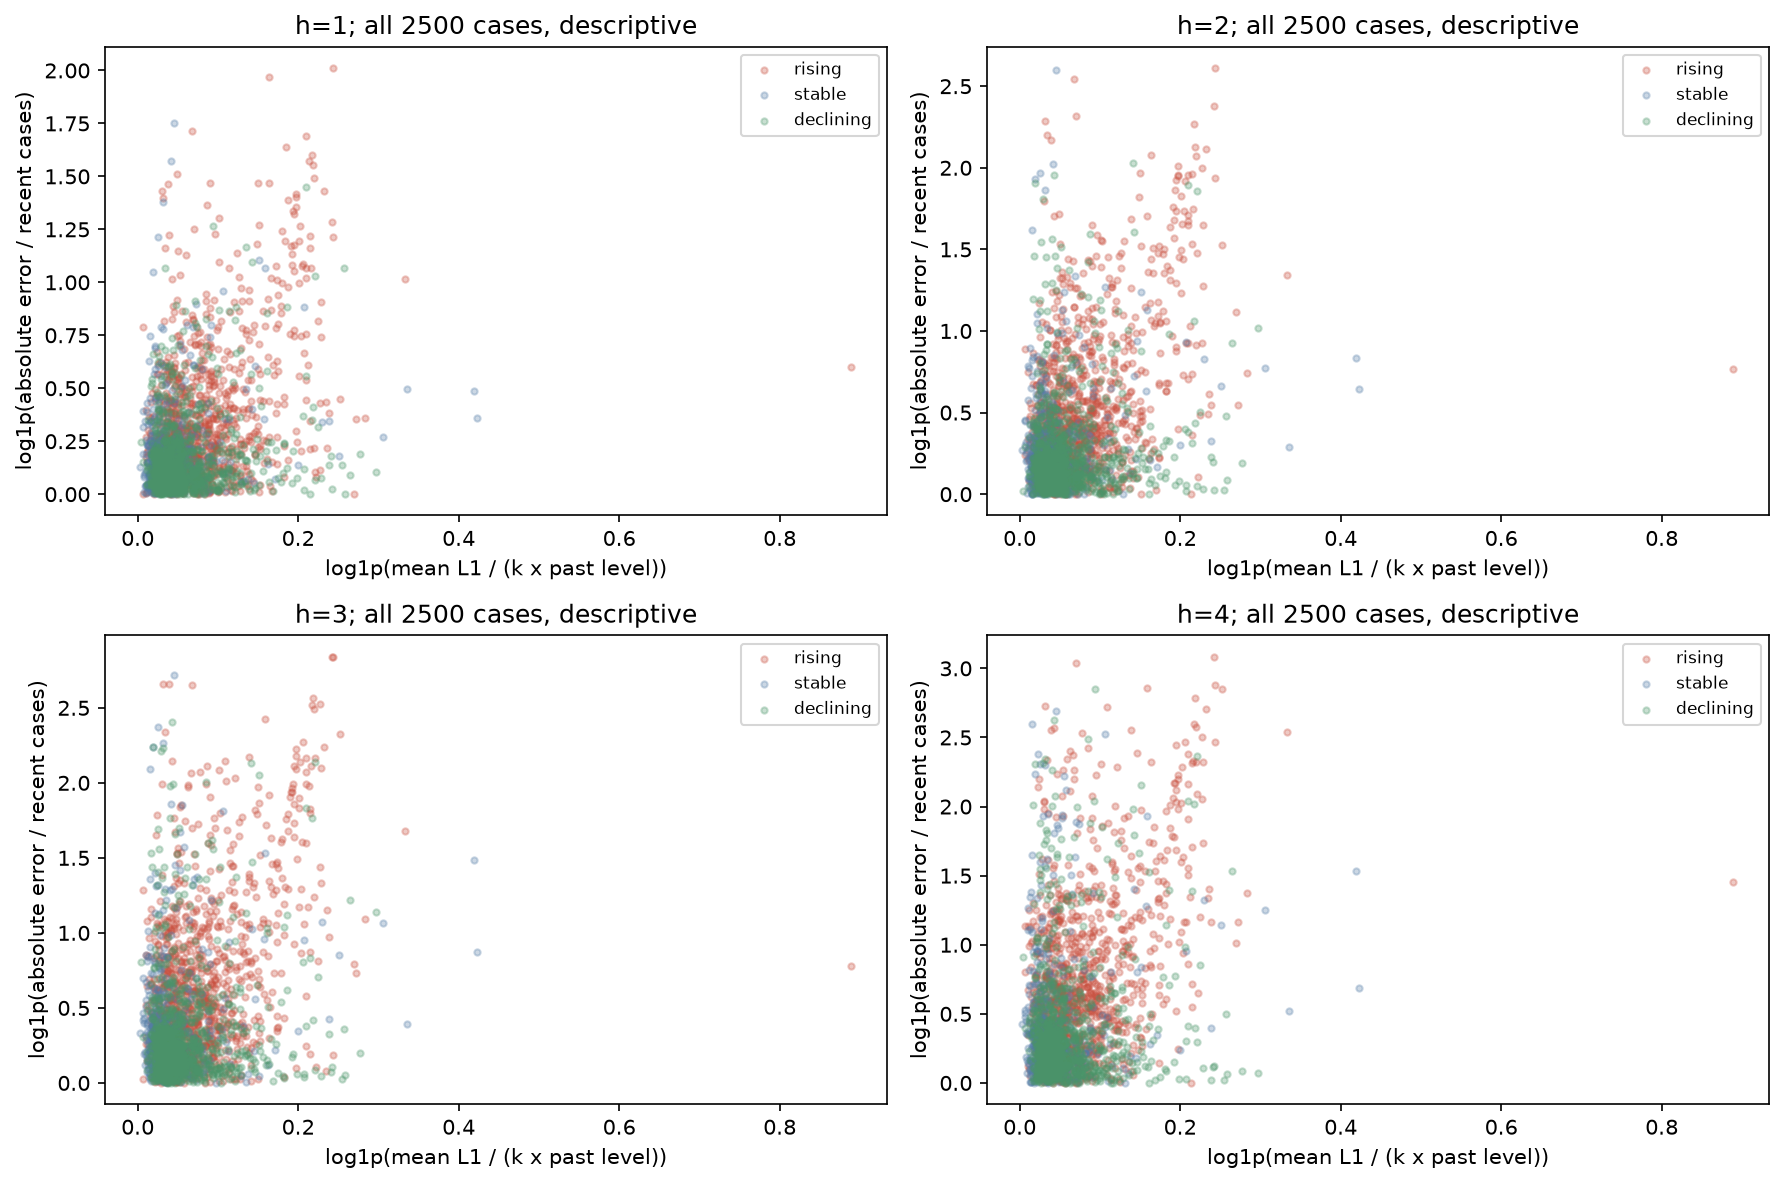

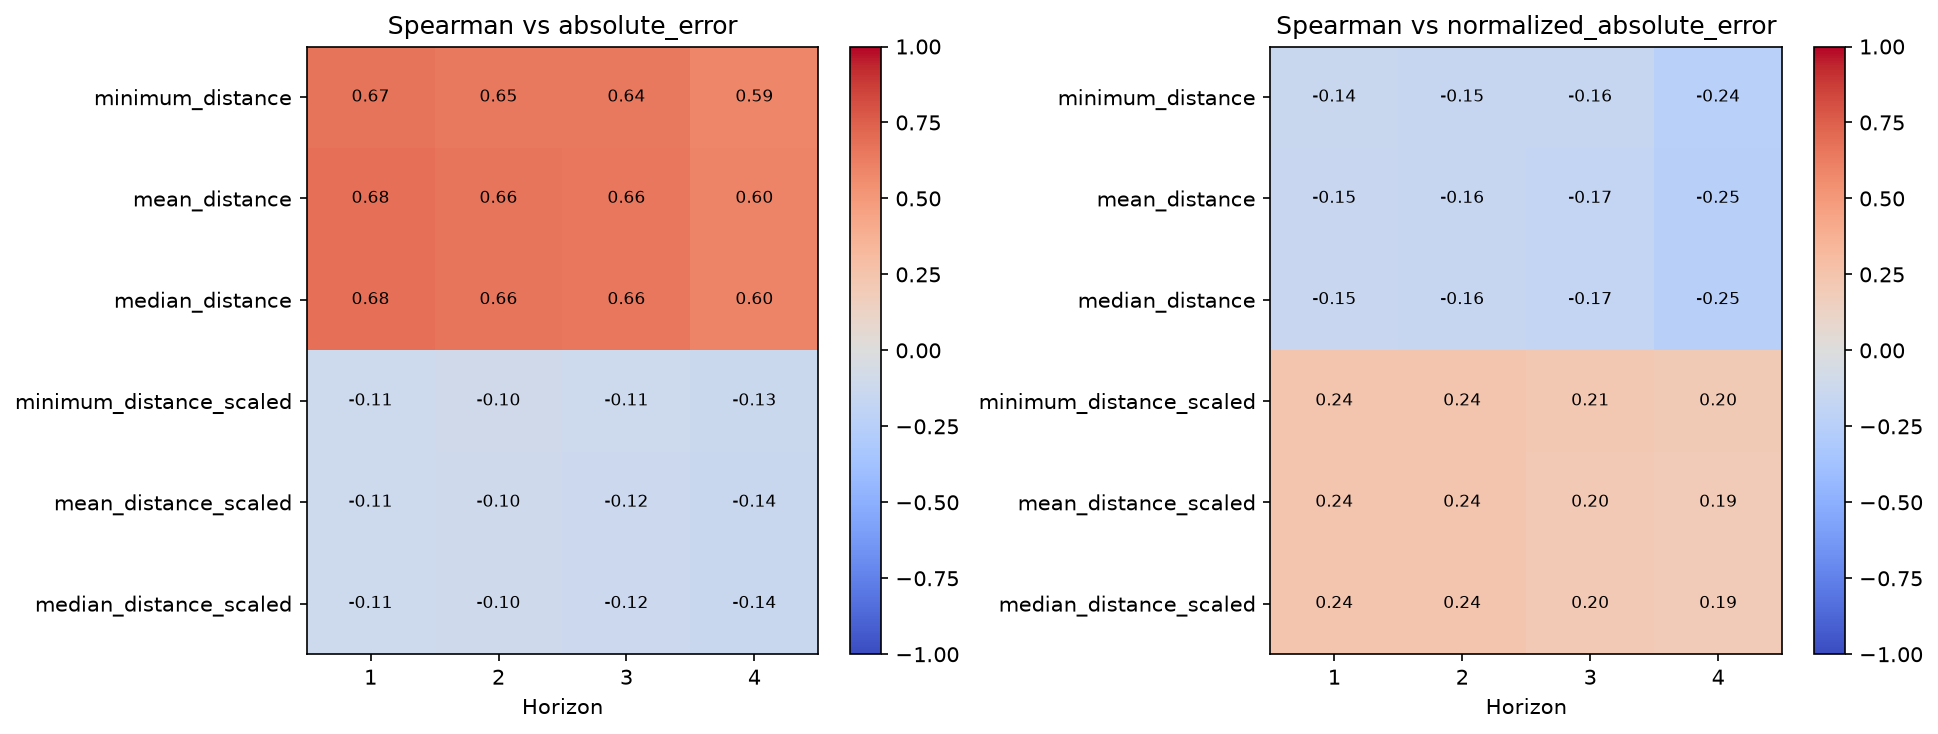

In [2]:
display(corr.loc[corr.seed.eq(0)&corr.scope.eq('all')&corr.stratum.isin(['all','context_adjusted'])&corr.distance.eq('mean_distance_scaled')&corr.error.eq('normalized_absolute_error')])
figure('01_distance_error')
figure('03_correlations')

## 2. Distance bins và khác biệt theo điều kiện dịch

Quintile cuts được tính trên **training cases một lần**, không dùng quantiles của test hoặc error để chọn ngưỡng. Ties giữ cùng bin; không ép năm nhóm bằng nhau nếu ngưỡng trùng.

Boxplots và extreme rates dưới đây dùng thời kỳ test. Extreme=absolute error/scale_origin >1. Các strata là phase/case-level chỉ dùng dữ liệu tại origin, theo cùng quy tắc E4. Không suy ra causal effects.

,scope,horizon,distance_bin,cases,states,MAE,normalized_MAE,extreme_rate,median_scaled_distance
20,test,1,1,337,50,3167.164688,0.238333,0.029674,0.025223
21,test,1,2,228,49,3781.013158,0.247068,0.030702,0.040575
22,test,1,3,192,48,3526.377604,0.295311,0.057292,0.055210
23,test,1,4,237,50,7536.135021,0.384642,0.101266,0.080479
24,test,1,5,156,48,6842.852564,0.561162,0.153846,0.136555
25,test,2,1,337,50,5728.792285,0.458698,0.077151,0.025223
26,test,2,2,228,49,8400.739035,0.496336,0.078947,0.040575
27,test,2,3,192,48,6087.505208,0.558330,0.151042,0.055210
28,test,2,4,237,50,10485.164557,0.668419,0.185654,0.080479
29,test,2,5,156,48,9897.073718,0.847779,0.256410,0.136555


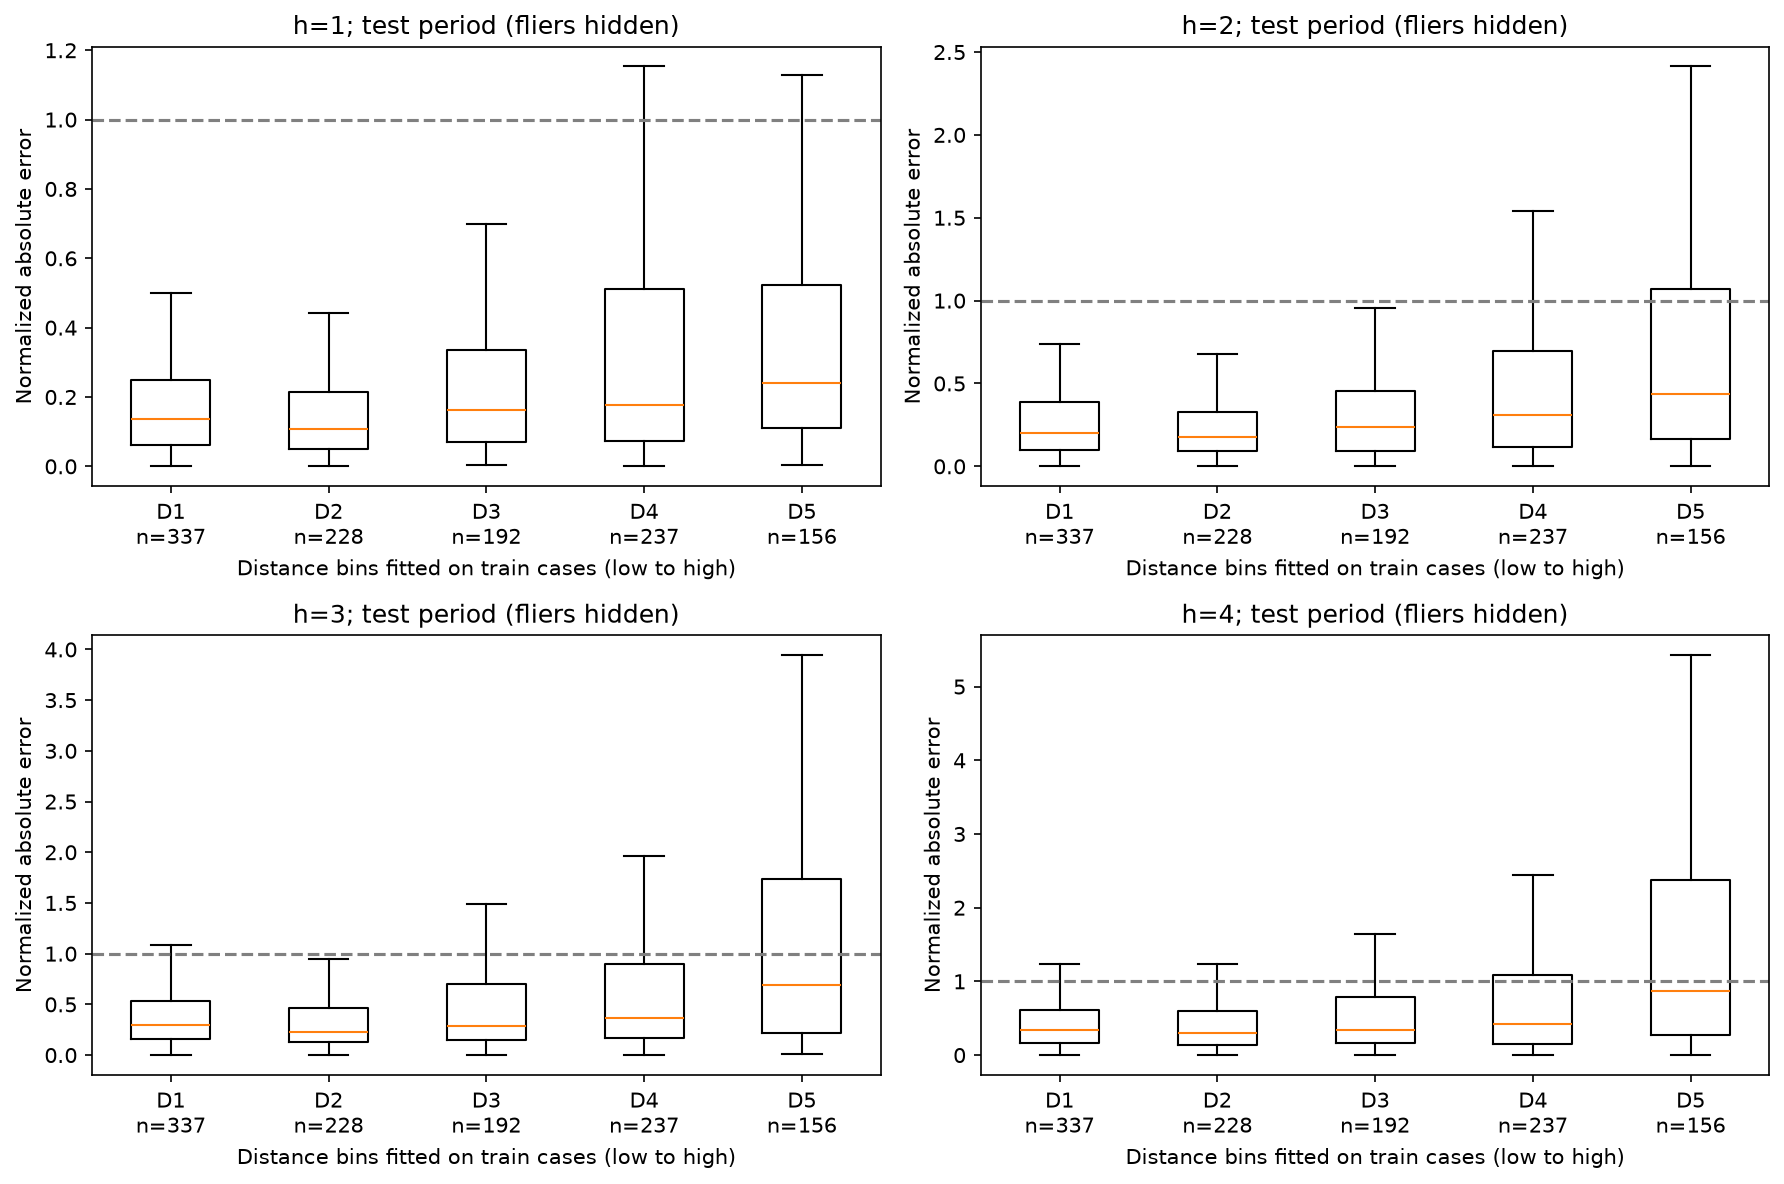

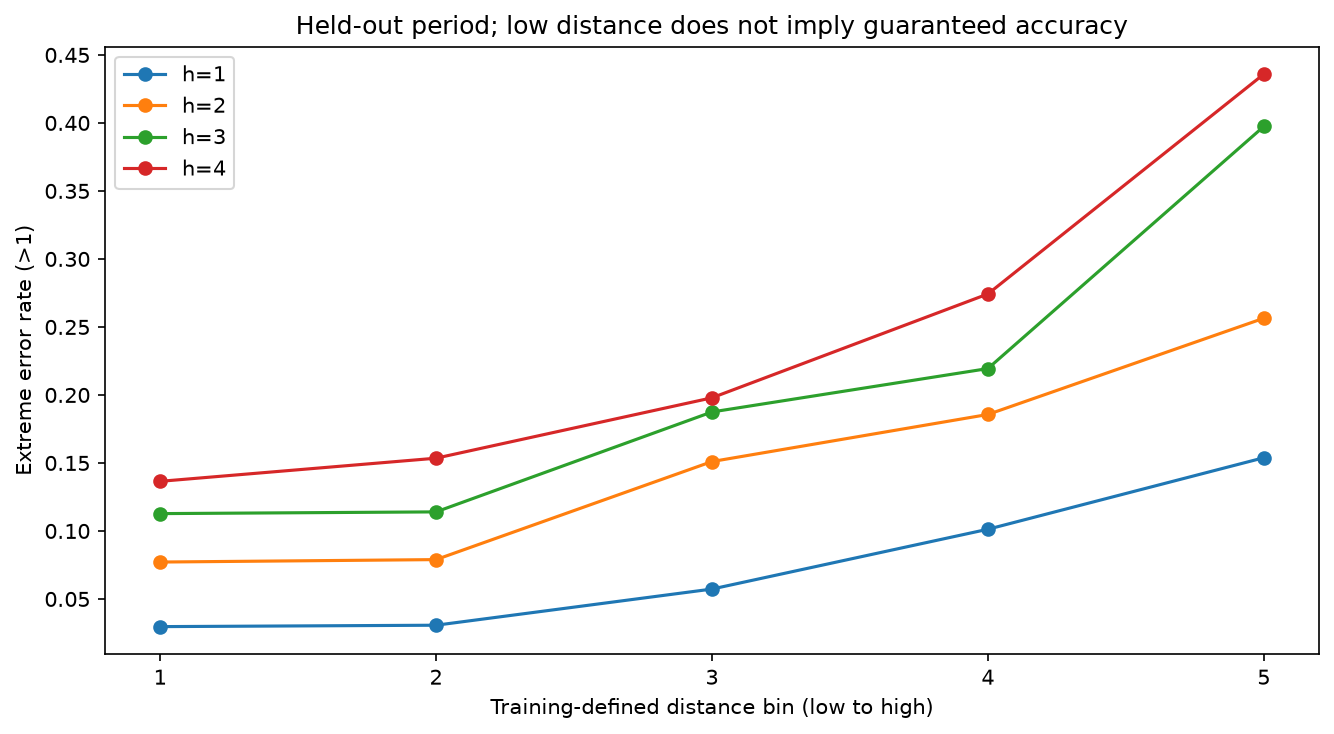

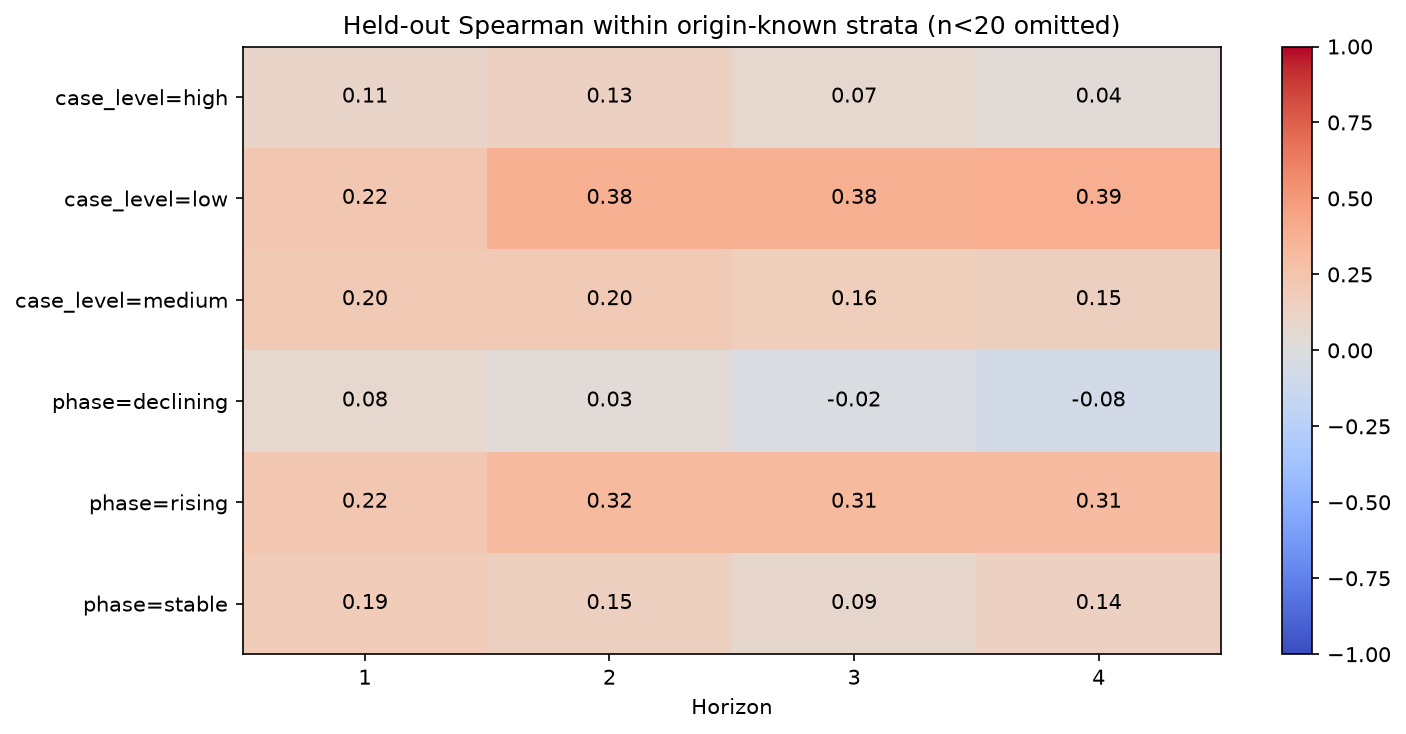

In [3]:
display(groups.loc[groups.scope.eq('test')])
figure('02_error_by_distance_bin')
figure('04_extreme_error_rates')
figure('07_conditional_correlations')

## 3. Matching tốt vẫn có thể forecast sai lớn

Good match định nghĩa trước: scaled mean distance ≤q20 của training cases. CSV giữ tất cả instances vừa good-match vừa extreme-error. Hình chọn hậu nghiệm bốn cases lỗi lớn ở bốn bang khác nhau, dùng để giải thích failures, không đại diện accuracy điển hình.

,series,forecast_origin,horizon,mean_distance_scaled,prediction,actual,normalized_absolute_error,phase,case_level
0,South Carolina,2021-12-25,4,0.031530,9057.5,112585.0,14.334026,rising,medium
1,South Carolina,2021-12-25,3,0.031530,9127.0,104873.0,13.256629,rising,medium
2,Nevada,2021-12-25,4,0.016027,6040.0,65307.0,12.449089,stable,medium
3,Hawaii,2021-11-27,4,0.023269,571.0,8410.0,9.792630,stable,low
4,Arkansas,2021-12-25,3,0.026282,7610.5,62776.0,9.687505,stable,medium
5,Oklahoma,2021-12-25,4,0.032653,7017.5,82524.0,9.441263,declining,medium
6,Utah,2021-12-25,4,0.030131,3678.5,75655.0,9.118741,declining,medium
7,Oregon,2021-12-25,4,0.018777,5249.0,57501.0,9.055806,declining,medium
8,Arkansas,2021-12-25,4,0.026282,7674.0,59044.0,9.020985,stable,medium
9,North Carolina,2021-12-25,4,0.031791,14631.0,201450.0,8.970900,stable,high


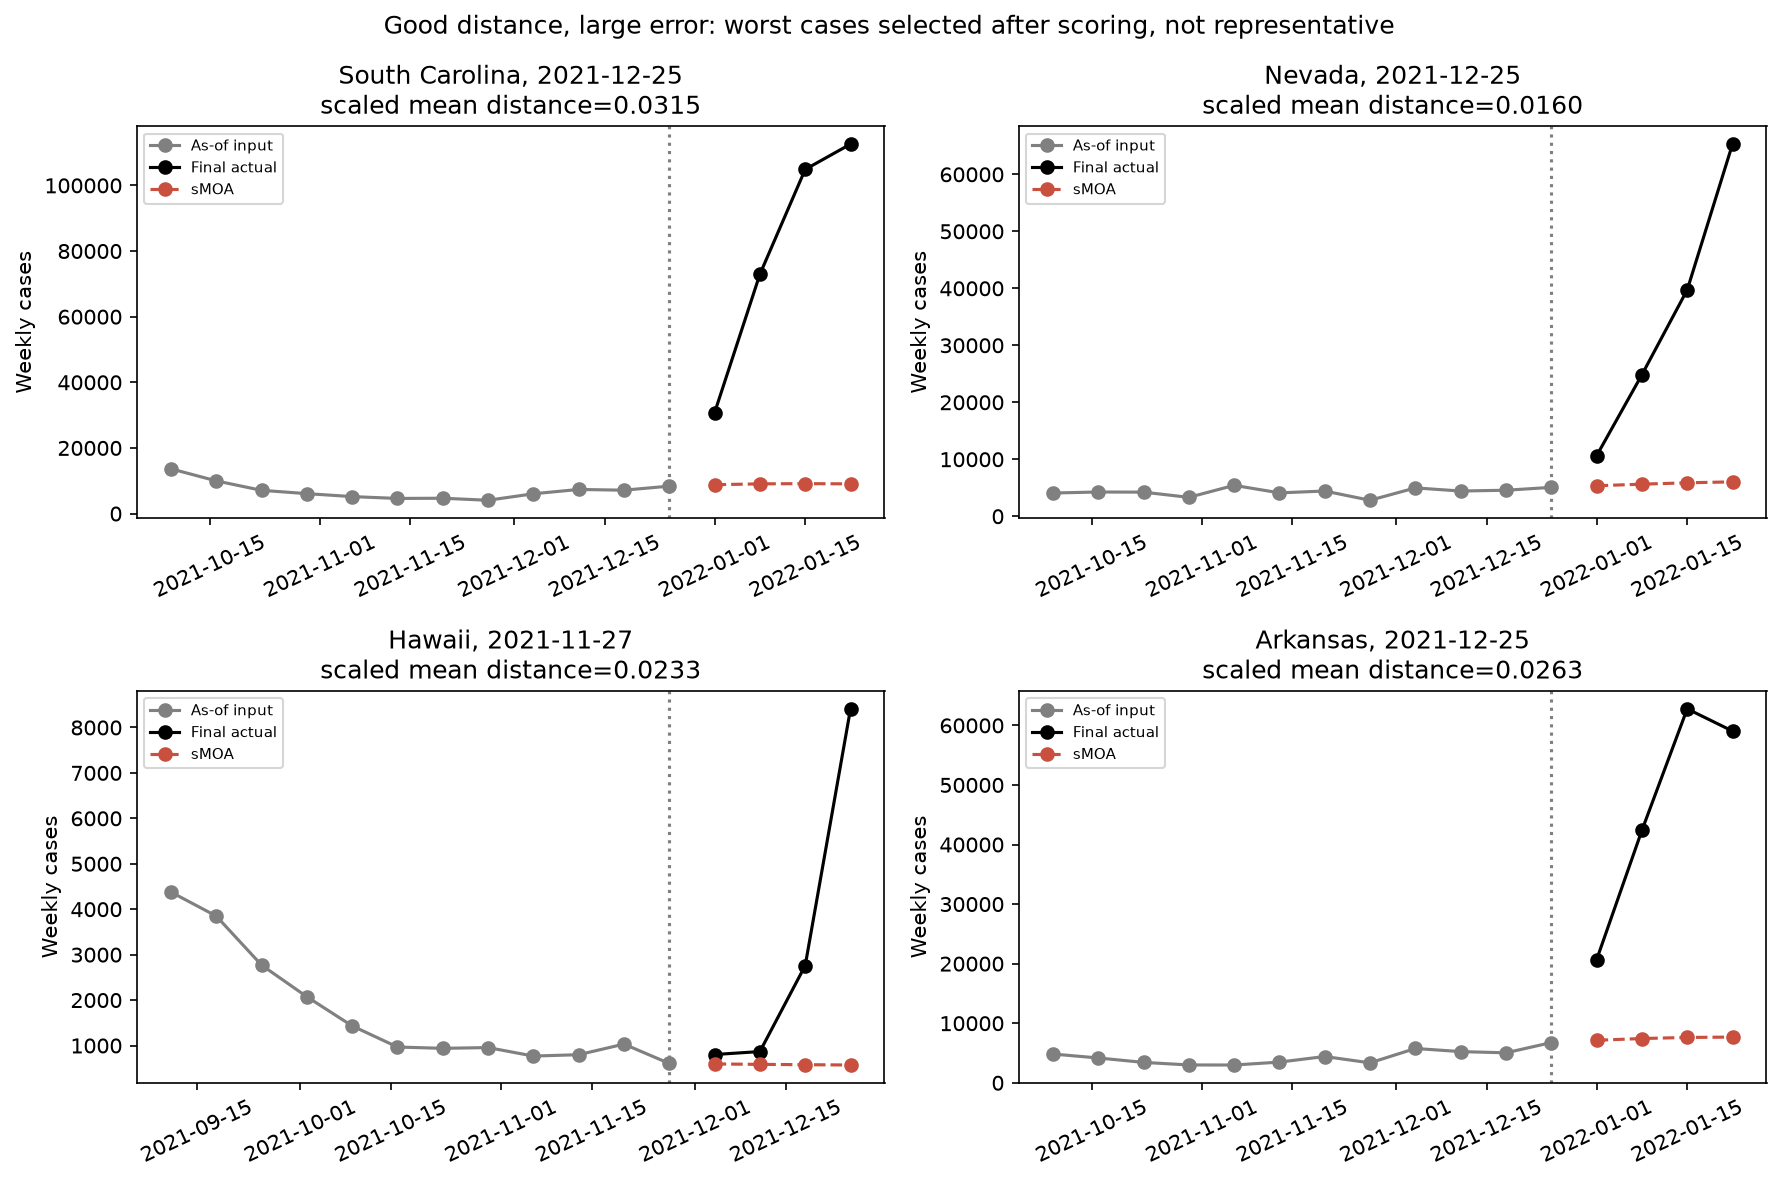

In [4]:
display(table('counterexamples')[['series','forecast_origin','horizon','mean_distance_scaled','prediction','actual','normalized_absolute_error','phase','case_level']].head(12))
figure('06_good_match_failures')

## 4. Distance có giúp chẩn đoán rủi ro trên thời kỳ sau?

- Train cases có **cả bốn targets ≤2020-12-31**; test origins ≥2021-01-01; origins ở buffer không dùng train/test.
- Risk training labels lấy từ **snapshot JHU tại origin test đầu tiên**, không lấy final revisions ở tương lai. Model fit trước issuance của lần test đó và giữ nguyên cho mọi origin sau.
- Ba diagnostic scores: distance-only, origin-context-only, context+distance. Chúng dự đoán nguy cơ sMOA sai lớn, không dự báo case counts và không thay mô hình sMOA.
- Standardization fit trên train; logistic L2=1 cố định, fit riêng từng horizon; không tune theo test.
- AUROC đánh giá ranking, AP so với extreme prevalence, Brier đánh giá xác suất. CI/deltas bootstrap nguyên bang (500 resamples) giữ dependency trong bang; không loại hết phụ thuộc quốc gia theo thời gian.

,horizon,diagnostic,train_cases,test_cases,test_extreme_rate,AUROC,AUROC_lo,AUROC_hi,average_precision,Brier,fit_status,delta_AUROC_vs_context,delta_AUROC_lo,delta_AUROC_hi,delta_Brier_vs_context,delta_Brier_lo,delta_Brier_hi
0,1,distance_only,1300,1150,0.066087,0.699402,0.629403,0.753341,0.144722,0.065436,ok,NaN,NaN,NaN,NaN,NaN,NaN
1,1,context_only,1300,1150,0.066087,0.745038,0.695171,0.787706,0.259534,0.058971,ok,NaN,NaN,NaN,NaN,NaN,NaN
2,1,context_plus_distance,1300,1150,0.066087,0.753271,0.706646,0.793569,0.252041,0.058972,ok,0.008233,0.003110,0.014314,4.030431e-07,-0.000624,0.000837
3,2,distance_only,1300,1150,0.136522,0.656821,0.617697,0.691381,0.246116,0.117411,ok,NaN,NaN,NaN,NaN,NaN,NaN
4,2,context_only,1300,1150,0.136522,0.660599,0.605396,0.708360,0.270914,0.116701,ok,NaN,NaN,NaN,NaN,NaN,NaN
5,2,context_plus_distance,1300,1150,0.136522,0.659746,0.608789,0.709018,0.282723,0.114753,ok,-0.000853,-0.011293,0.009384,-1.947706e-03,-0.003685,-0.000567
6,3,distance_only,1300,1150,0.186087,0.664071,0.629299,0.695902,0.371541,0.140454,ok,NaN,NaN,NaN,NaN,NaN,NaN
7,3,context_only,1300,1150,0.186087,0.648325,0.592917,0.701294,0.356982,0.146254,ok,NaN,NaN,NaN,NaN,NaN,NaN
8,3,context_plus_distance,1300,1150,0.186087,0.649538,0.593729,0.701916,0.360392,0.145774,ok,0.001213,-0.000375,0.002936,-4.795438e-04,-0.000714,-0.000276
9,4,distance_only,1300,1150,0.219130,0.660034,0.632970,0.688750,0.393559,0.161580,ok,NaN,NaN,NaN,NaN,NaN,NaN


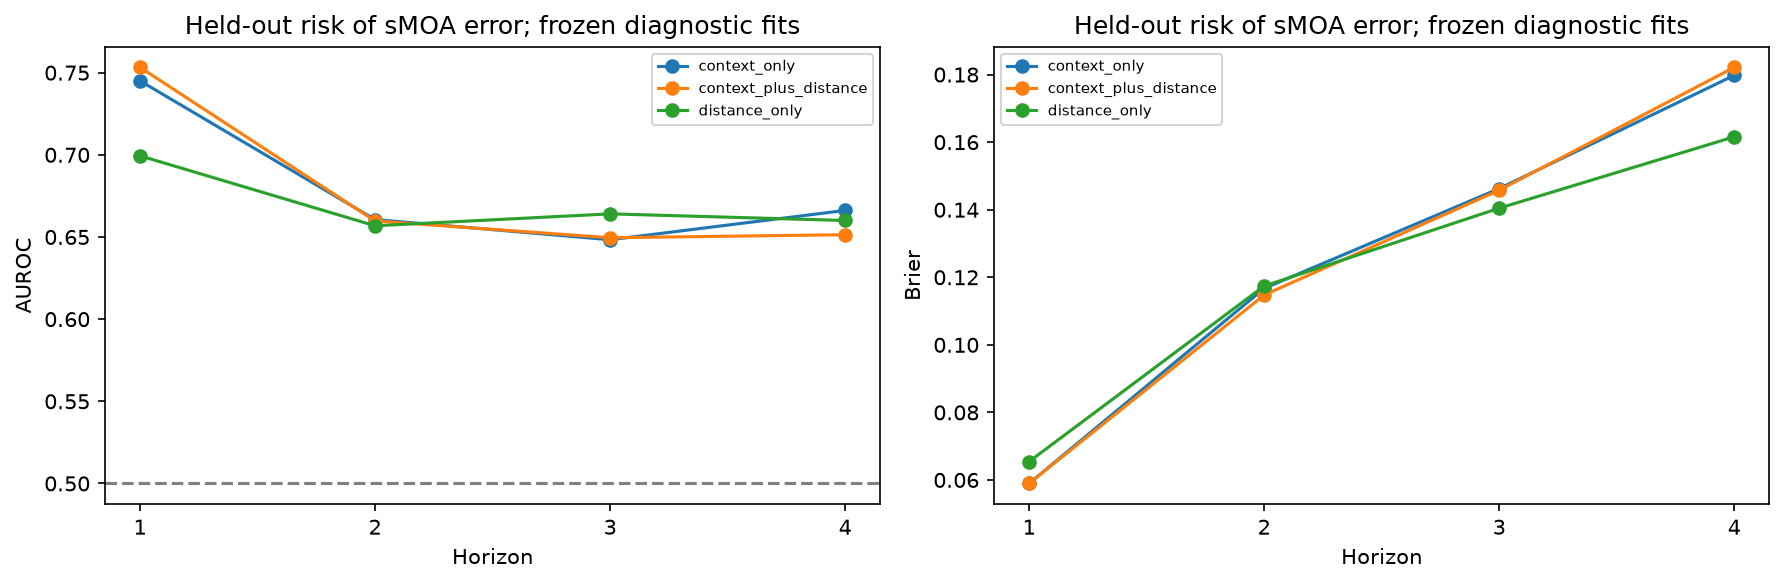

,horizon,delta_AUROC_vs_context,delta_AUROC_lo,delta_AUROC_hi,delta_Brier_vs_context,delta_Brier_lo,delta_Brier_hi
2,1,0.008233,0.003110,0.014314,4.030431e-07,-0.000624,0.000837
5,2,-0.000853,-0.011293,0.009384,-1.947706e-03,-0.003685,-0.000567
8,3,0.001213,-0.000375,0.002936,-4.795438e-04,-0.000714,-0.000276
11,4,-0.014782,-0.024980,-0.006248,2.378663e-03,0.001629,0.003113


In [5]:
display(risk)
figure('05_risk_diagnostics')
display(risk.loc[risk.diagnostic.eq('context_plus_distance'), ['horizon','delta_AUROC_vs_context','delta_AUROC_lo','delta_AUROC_hi','delta_Brier_vs_context','delta_Brier_lo','delta_Brier_hi']])

## 5. Độ nhạy giữa synthetic banks

Hai seeds E2 khác có sẵn min/median distance. Đây là **secondary median-distance check** trên cùng N/k/m/targets, không giả rằng đã đo mean distance ở các seeds đó. Primary exact mean-distance replay chỉ dùng seed0.

In [6]:
display(corr.loc[corr.stratum.eq('secondary_seed')])

,seed,scope,stratum,horizon,distance,error,cases,states,rho,lo,hi
129,1,all,secondary_seed,1,median_distance_scaled,normalized_absolute_error,2500,50,0.232287,NaN,NaN
130,1,all,secondary_seed,2,median_distance_scaled,normalized_absolute_error,2500,50,0.237488,NaN,NaN
131,1,all,secondary_seed,3,median_distance_scaled,normalized_absolute_error,2500,50,0.205480,NaN,NaN
132,1,all,secondary_seed,4,median_distance_scaled,normalized_absolute_error,2500,50,0.192050,NaN,NaN
133,2,all,secondary_seed,1,median_distance_scaled,normalized_absolute_error,2500,50,0.233266,NaN,NaN
134,2,all,secondary_seed,2,median_distance_scaled,normalized_absolute_error,2500,50,0.235115,NaN,NaN
135,2,all,secondary_seed,3,median_distance_scaled,normalized_absolute_error,2500,50,0.202657,NaN,NaN
136,2,all,secondary_seed,4,median_distance_scaled,normalized_absolute_error,2500,50,0.187752,NaN,NaN


## Báo cáo và giới hạn

Giữ nguyên numerical core, gồm variance-filter roundoff đã được E2 audit. Không khẳng định Python/R numerical parity, causal association, hoặc khả năng cảnh báo ngoài fixed temporal split này. Cases/instances/correlations/risk scores nằm trong một output folder; code/input/artifact checksums ở protocol.json và progress.json.

In [7]:
display(Markdown((OUT/'report.md').read_text().split('![')[0]))

# Experiment 5 — Analogue quality vs forecast accuracy

Primary: paper parameters N=18.387 attempts/family, k=5, m=4.422, GAM, omit bridge, seed0. 50 states ×50 fixed origins ×4 horizons =10.000 forecast instances. No BO, synthetic generation or sMOA forecast change.

Exact replay verified 10,000 point forecasts and all stored min/median/max distances. Mean distance was filled by exact top-m replay using the existing memmap bank. Other E2 seeds are secondary median-distance sensitivity only.

## Definitions and chronology

- L1 search uses unchanged GAM history differences. Scale normalization divides the resulting distance by k×mean(last 6 floored raw values); it does not change which analogues are selected.
- Errors normalize by mean(last 4 floored observations), as Experiment 4. Distances/errors use related origin scales: ratio correlations can be induced by scale. Compare raw/scaled metrics, strata, adjusted rank association and held-out diagnostic performance together.
- One observation at each horizon per state/origin. Spearman is reported separately per horizon; pooled horizon analysis uses one mean-error record per case, never 10.000 independent cases. No naive independent-row p-values.
- Training cases have all targets ≤2020-12-31; test origins ≥2021-01-01. Training labels come only from the first test-origin historical JHU vintage, not future final revisions. The diagnostic is frozen for all later origins; final truth is used to evaluate test risk.
- First test origin: 2021-01-23; 1300 training, 1150 test, 50 embargo cases. Bin boundaries fitted only to training cases: [0.03404202991481659, 0.046987841604100876, 0.06471020847286112, 0.10581278591592232].

## Does closer matching imply smaller error?

| horizon | cases | rho | lo | hi |
| --- | --- | --- | --- | --- |
| 1.000 | 2,500.000 | 0.237 | 0.198 | 0.272 |
| 2.000 | 2,500.000 | 0.239 | 0.197 | 0.273 |
| 3.000 | 2,500.000 | 0.204 | 0.167 | 0.240 |
| 4.000 | 2,500.000 | 0.191 | 0.145 | 0.230 |

Context-adjusted rank association (controls: both past levels, growth, volatility, history length and phase):

| horizon | rho |
| --- | --- |
| 1.000 | 0.010 |
| 2.000 | 0.006 |
| 3.000 | -0.012 |
| 4.000 | -0.038 |

Scaled-mean Spearman spans 0.191..0.239; after context adjustment -0.038..0.010. This separates unconditional association from remaining rank association; it does not establish causality or rule out nonlinear signals.

Full raw/scaled minimum/mean/median and error-scale combinations, train/test scopes, strata and secondary seeds are in correlations.csv. Their comparisons are descriptive; no post-hoc best metric is promoted to a selected risk signal.

## Can a good match still fail?

Good matching is fixed at training-case q20=0.034042 for scaled mean distance; a large error is absolute error/origin scale >1. All matching-small/error-large cases remain in counterexamples.csv; the figure picks four extreme distinct states after scoring.

All cases (descriptive):

| horizon | cases | extreme_rate | normalized_MAE |
| --- | --- | --- | --- |
| 1.000 | 615.000 | 0.020 | 0.227 |
| 2.000 | 615.000 | 0.086 | 0.438 |
| 3.000 | 615.000 | 0.148 | 0.650 |
| 4.000 | 615.000 | 0.200 | 0.858 |

Held-out period only:

| horizon | cases | extreme_instances | extreme_rate |
| --- | --- | --- | --- |
| 1.000 | 337.000 | 10.000 | 0.030 |
| 2.000 | 337.000 | 26.000 | 0.077 |
| 3.000 | 337.000 | 38.000 | 0.113 |
| 4.000 | 337.000 | 46.000 | 0.136 |

## Does distance help diagnose risk on a later period?

| horizon | diagnostic | train_cases | test_cases | AUROC | average_precision | Brier |
| --- | --- | --- | --- | --- | --- | --- |
| 1.000 | distance_only | 1,300.000 | 1,150.000 | 0.699 | 0.145 | 0.065 |
| 1.000 | context_only | 1,300.000 | 1,150.000 | 0.745 | 0.260 | 0.059 |
| 1.000 | context_plus_distance | 1,300.000 | 1,150.000 | 0.753 | 0.252 | 0.059 |
| 2.000 | distance_only | 1,300.000 | 1,150.000 | 0.657 | 0.246 | 0.117 |
| 2.000 | context_only | 1,300.000 | 1,150.000 | 0.661 | 0.271 | 0.117 |
| 2.000 | context_plus_distance | 1,300.000 | 1,150.000 | 0.660 | 0.283 | 0.115 |
| 3.000 | distance_only | 1,300.000 | 1,150.000 | 0.664 | 0.372 | 0.140 |
| 3.000 | context_only | 1,300.000 | 1,150.000 | 0.648 | 0.357 | 0.146 |
| 3.000 | context_plus_distance | 1,300.000 | 1,150.000 | 0.650 | 0.360 | 0.146 |
| 4.000 | distance_only | 1,300.000 | 1,150.000 | 0.660 | 0.394 | 0.162 |
| 4.000 | context_only | 1,300.000 | 1,150.000 | 0.666 | 0.410 | 0.180 |
| 4.000 | context_plus_distance | 1,300.000 | 1,150.000 | 0.651 | 0.395 | 0.182 |

Increment over origin-context diagnostic, using exactly the same held-out targets (positive delta AUROC / negative delta Brier favors adding distance):

| horizon | delta_AUROC_vs_context | delta_AUROC_lo | delta_AUROC_hi | delta_Brier_vs_context | delta_Brier_lo | delta_Brier_hi |
| --- | --- | --- | --- | --- | --- | --- |
| 1.000 | 0.008 | 0.003 | 0.014 | 0.000 | -0.001 | 0.001 |
| 2.000 | -0.001 | -0.011 | 0.009 | -0.002 | -0.004 | -0.001 |
| 3.000 | 0.001 | -0.000 | 0.003 | -0.000 | -0.001 | -0.000 |
| 4.000 | -0.015 | -0.025 | -0.006 | 0.002 | 0.002 | 0.003 |

Risk scores are diagnostics for forecast failure, not additional case-count forecasting models. Logistic standardization is fitted on train only; L2 penalty fixed at 1; no test tuning. AP should be compared with test extreme prevalence in risk_scores.csv; Brier measures overall probability accuracy, not calibration alone; AUROC measures ranking.

Small positive/negative incremental scores are horizon-dependent: a distance-only association is not proof of additional value beyond context. Read paired intervals and both ranking/probability metrics. No best horizon or diagnostic is selected for a production alert from this test.

## Limits

- Distance similarity represents past trajectories, not future mechanisms. Novel waves, phase changes and reporting zeros can break that link; observations here do not establish causality.
- State-cluster percentile intervals use 500 resamples retaining origins within state. They do not remove national temporal dependence; one fixed time split is not external validation. Strata with <20 cases or constant inputs have NA correlation.
- The primary mean-distance result uses one training bank. Two other E2 banks support only a median-distance check; no mean distance was invented for them.
- This preserves the existing numerical core, including its floating-point variance filter, to match E2/E4. Python/R numerical parity is not established.
- Quartile/quantile cuts are frozen from early-period cases and may have imbalanced/empty groups on test. Hidden boxplot outlier markers affect display only; all instances remain in scores and scatter.
- Confidence intervals are descriptive, without multiple-comparison adjustment. Conditional associations and one diagnostic family do not prove actionable risk prediction or absence of every possible distance-based signal. Read incremental held-out AUROC/Brier before treating distance as a warning signal.

